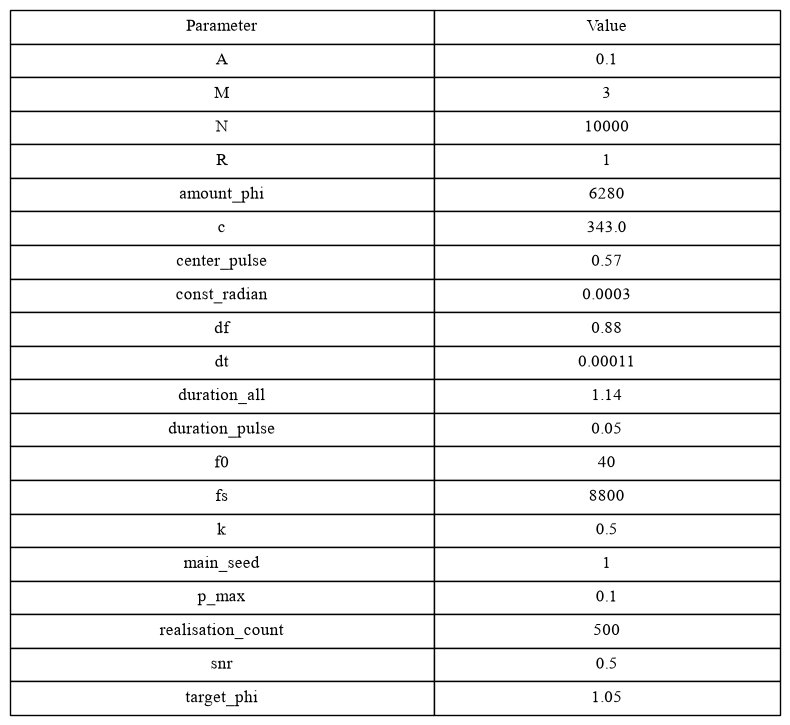

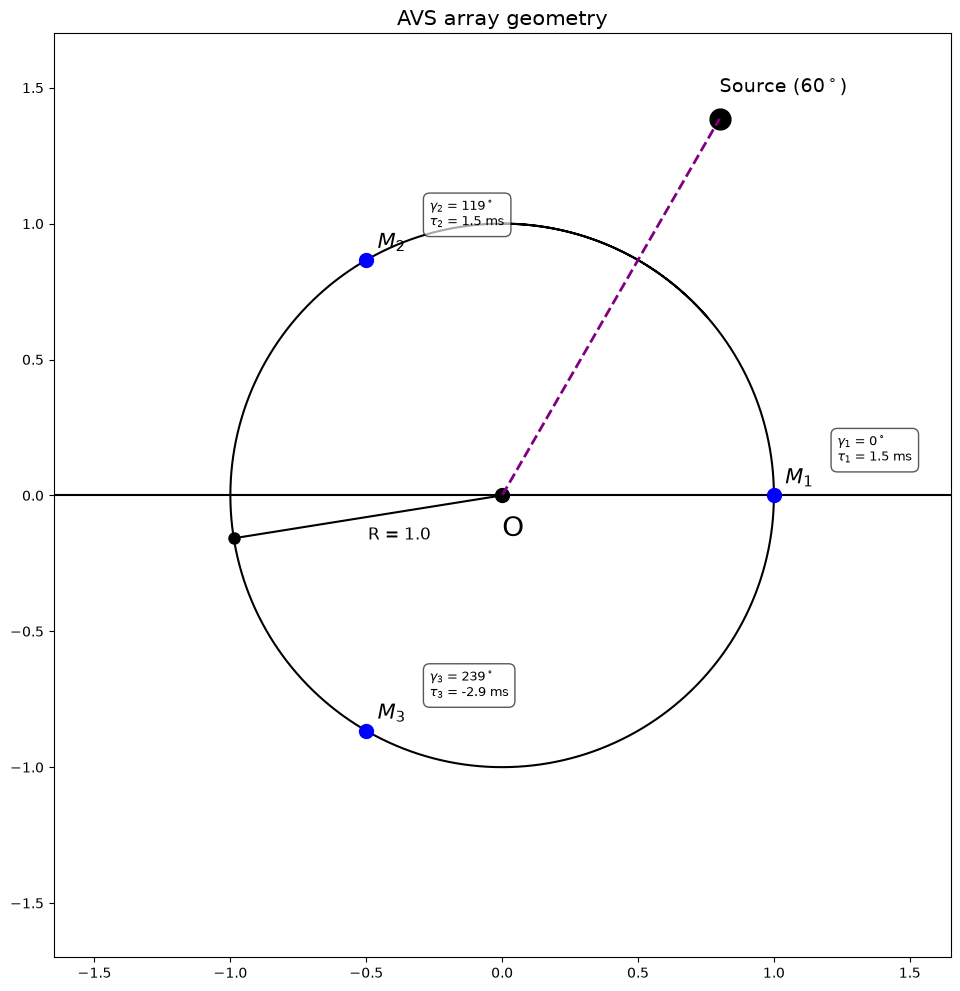

In [1]:
import os
import time
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
from copy import copy
import src.config as config
import src.spectrum as spectrum
import src.signals as signals
import src.model as model
import os
import src.plotting as plotting
import src.pseudospectrum as pseudospectrum
import src.experement as experement
import src.steerings as steerings
configs = config.init_rng()
path = "attachment/images/notebook"
os.makedirs(path,exist_ok=True)

plotting.config_table(configs)
plotting.show_geometry_avp(configs)

In [2]:

lorenth_pulse = signals.lorenth(configs)
pulse_signal_copy = lorenth_pulse.copy()
energy_pulse = signals.calculate_energy(lorenth_pulse, configs.time_vector)

sin_signal = signals.sinus(configs)
energy_sinus = signals.calculate_energy(sin_signal, configs.time_vector)
print(energy_pulse)
print(energy_sinus)

0.0007851730324905919
0.005687095218249014


In [3]:


spectrum_pulse = spectrum.fft(lorenth_pulse.copy())
f_target = 40
#f99 = spectrum.f_99(configs.freq_vector, spectrum_pulse)
en_signal = signals.calculate_energy(lorenth_pulse, configs.time_vector)

K = 2
B = K*f_target


spectrum_filtering_signal = spectrum.cut_spectrum(spectrum_pulse, B, configs.fs)

back_signal = spectrum.ifft(spectrum_filtering_signal)
energy_filt_pulse_value = signals.calculate_energy(back_signal, configs.time_vector)
f_rms_new = spectrum.f_rms(spectrum.fft(back_signal),configs)




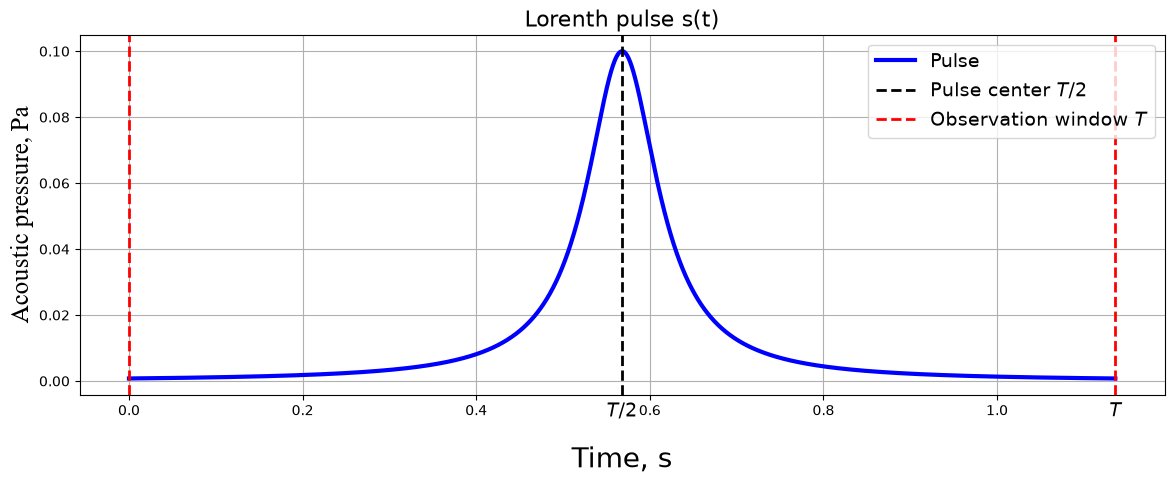

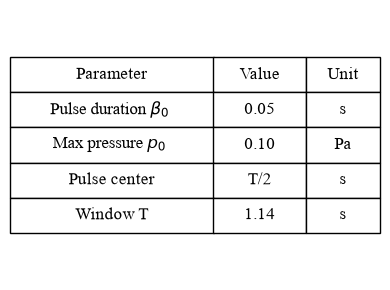

In [4]:
# Построение графика
title_main = "Pulse signal s(t)"
fig, ax = plt.subplots(1, 1, figsize = configs.fig_size)
fig.subplots_adjust(top=0.85, bottom=0.25)


ax.plot(
    configs.time_vector, lorenth_pulse,
    color="blue", linewidth=3, label="Pulse"
)

# Названия осей и заголовок
ax.set_xlabel("Time, s", labelpad=20, fontsize=20)
ax.set_ylabel("Acoustic pressure, Pa", fontsize=18, fontfamily="Times New Roman")
ax.set_title("Lorenth pulse s(t)", fontsize = 16)

# Центр импульса и отметки времени.
ax.axvline(
    configs.center_pulse,
    color="black", linestyle="--", linewidth=2,
    label="Pulse center $T/2$"
)
ax.axvline(
    0,
    color="red", linestyle="--", linewidth=2,
)
ax.axvline(
    configs.duration_all,
    color="red", linestyle="--", linewidth=2,
    label="Observation window $T$"
)
ax.text(
    configs.center_pulse, -0.02, r"$T/2$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=14
)
ax.text(
    configs.duration_all, -0.02, r"$T$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=14
)

ax.grid(True)
ax.legend(loc="upper right", fontsize=14)

# Параметры под графиком.
plt.savefig(fname = f"attachment/images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()

rows = [
    [r"Pulse duration $\beta_{\mathrm{0}}$ ", f"{configs.duration_pulse:.2f}", "s"],
    [r"Max pressure $p_{\mathrm{0}}$ ", f"{configs.A:.2f}", "Pa"],
    [r"Pulse center", f"T/2", "s"],
    [r"Window T",f"{configs.duration_all:.2f}","s"]]
plotting.create_and_save_table(rows, ["Parameter", "Value", "Unit"], f"attachment/images/notebook/table_{title_main}")

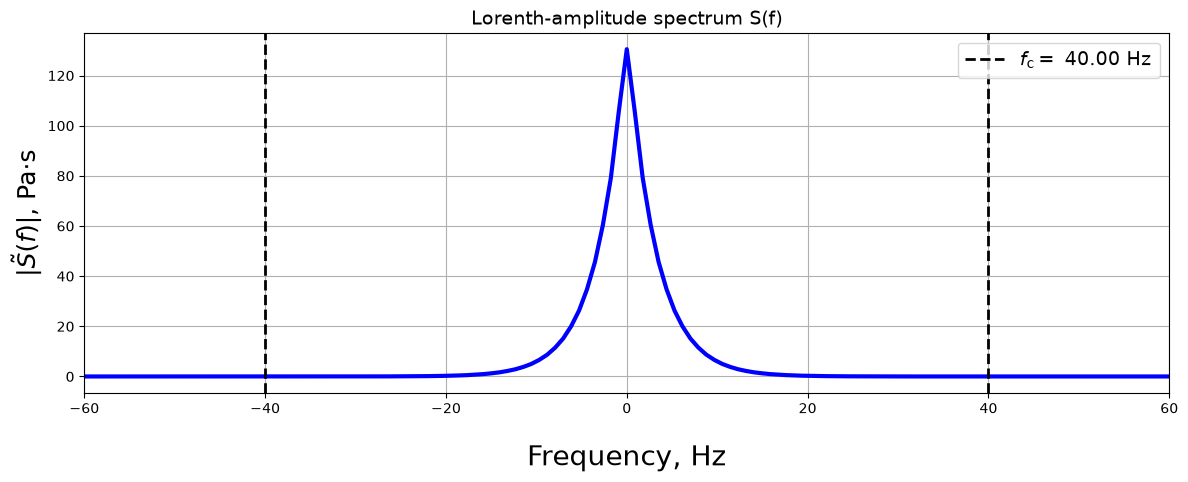

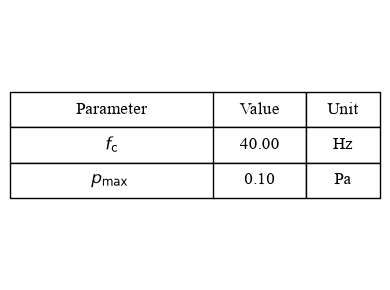

In [5]:


# Построение графика
title_main = "Amplitude spectrum S(f)"
fig, ax = plt.subplots(1, 1, figsize = configs.fig_size)
fig.subplots_adjust(top=0.85, bottom=0.25)


ax.plot(
    configs.freq_vector, np.abs(spectrum_pulse),
    color="blue", linewidth=3
)

# Названия осей и заголовок
ax.set_xlabel("Frequency, Hz", labelpad=20, fontsize=20)
ax.set_ylabel(r"$|\tilde{S}(f)|$, Pa·s", fontsize=18)

# Отметки среднеквадратической частоты.


ax.axvline(
    -f_target,
    color="black", linestyle="--", linewidth=2,
)
ax.set_title("Lorenth-amplitude spectrum S(f)", fontsize = 14)
ax.axvline(
    f_target,
    color="black", linestyle="--", linewidth=2,
    label=r"$f_\text{c} = $" + f" {f_target:.2f} Hz"
)

ax.legend(loc="upper right", fontsize=14)


# Параметры под графиком.

ax.set_xlim(-60,60)

ax.grid(True)
plt.savefig(fname = f"attachment/images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()

rows = [
    [r"$f_{\mathrm{c}}$",
 f"{f_target:.2f}", "Hz"],
    [r"$p_{\mathrm{max}}$ ", f"{configs.A:.2f}", "Pa"]]
plotting.create_and_save_table(rows, ["Parameter", "Value", "Unit"], f"attachment/images/notebook/table_{title_main}")

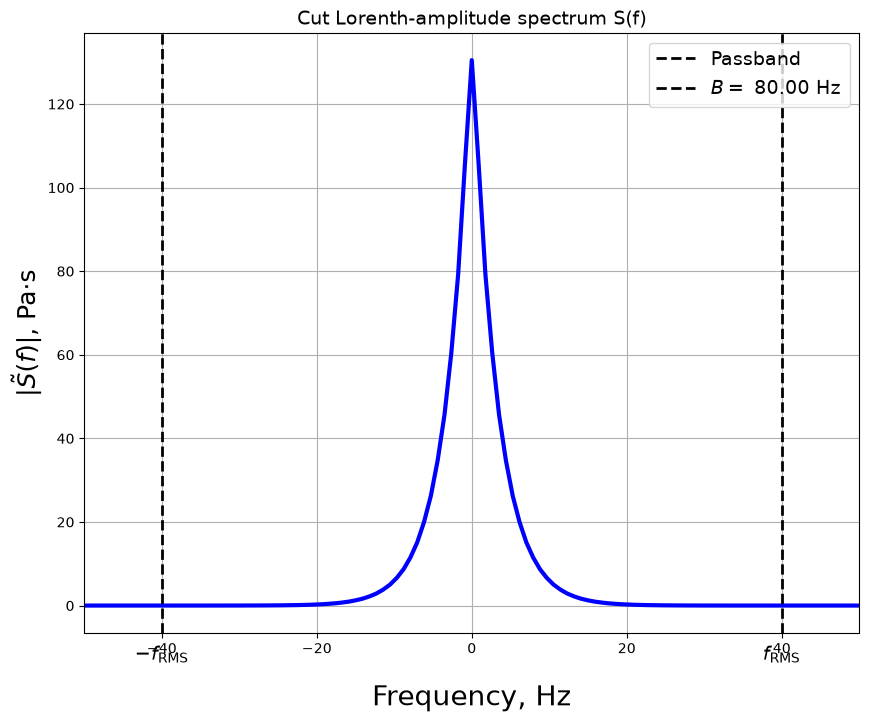

In [6]:


# Построение графика
title_main = "Filtered amplitude spectrum S(f)"
fig, ax = plt.subplots(1, 1, figsize = (10,10))
fig.subplots_adjust(top=0.85, bottom=0.25)


ax.plot(
    configs.freq_vector, np.abs(spectrum_filtering_signal),
    color="blue", linewidth=3
)

# Названия осей и заголовок
ax.set_xlabel("Frequency, Hz", labelpad=20, fontsize=20)
ax.set_ylabel(r"$|\tilde{S}(f)|$, Pa·s", fontsize=18)
ax.set_title("Cut Lorenth-amplitude spectrum S(f)", fontsize = 14)
# Границы полосы пропускания.


ax.axvline(
    -B/2,
    color="black", linestyle="--", linewidth=2,
    label="Passband"
)
ax.text(
    f_target, -0.02, r"$f_\text{RMS}$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=14)
ax.text(
    -f_target, -0.02, r"$-f_\text{RMS}$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=14
)
ax.axvline(
    B/2,
    color="black", linestyle="--", linewidth=2,
    label=r"$B  = $" + f" {B:.2f} Hz"
)

ax.legend(loc="upper right", fontsize=14)

# Параметры под графиком.

ax.set_xlim(-50,50)

ax.grid(True)
plt.savefig(fname = f"attachment/images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()

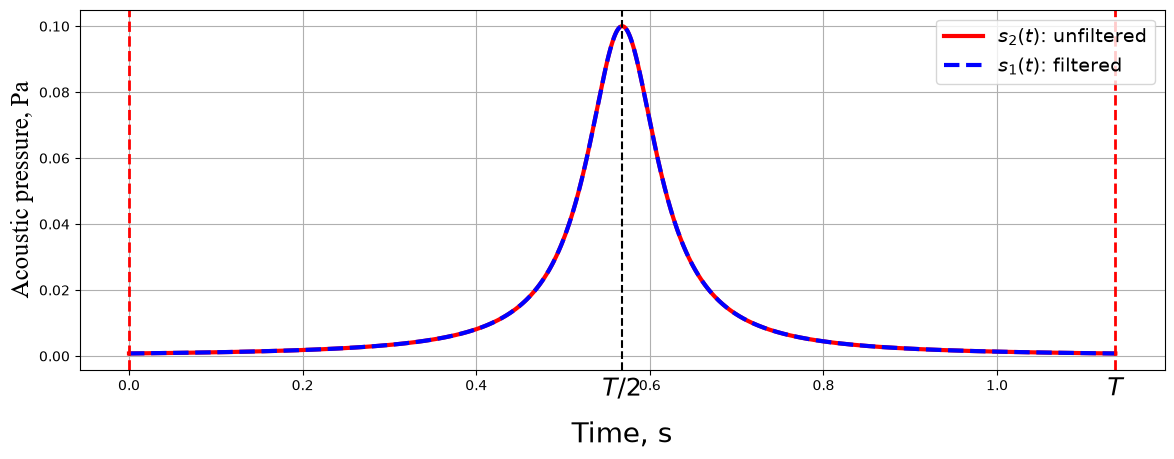

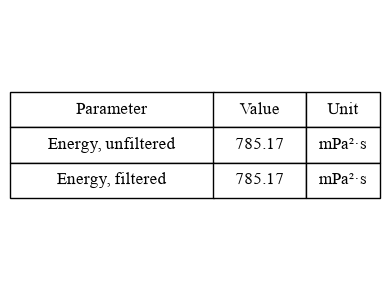

In [7]:


# Построение графика
title_main = "Filtered pulse signal P(t)"
fig, ax = plt.subplots(1, 1, figsize = configs.fig_size)
fig.subplots_adjust(top=0.85, bottom=0.25)

ax.plot(
    configs.time_vector, pulse_signal_copy,
    color="red", linewidth=3, label=r"$s_\text{2}(t)$: unfiltered"
)

ax.plot(
    configs.time_vector, back_signal,
    color="blue", linewidth=3, linestyle="--", label=r"$s_\text{1}(t)$: filtered"
)


# Названия осей и заголовок
ax.set_xlabel("Time, s", labelpad=20, fontsize=20)
ax.set_ylabel("Acoustic pressure, Pa", fontsize=18, fontfamily="Times New Roman")


# Центр импульса и отметки времени.
ax.axvline(
    configs.center_pulse,
    color="black", linestyle="--", linewidth=1.5,
)
ax.axvline(
    0,
    color="red", linestyle="--", linewidth=2,
)
ax.axvline(
    configs.duration_all,
    color="red", linestyle="--", linewidth=2
)
ax.text(
    configs.center_pulse, -0.02, r"$T/2$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)
ax.text(
    configs.duration_all, -0.02, r"$T$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)

ax.grid(True)
ax.legend(loc="upper right", fontsize=14)

# Параметры под графиком.

plt.savefig(fname = f"attachment/images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()

rows = [
    ["Energy, unfiltered", f"{energy_pulse*1e6:.2f}", r"mPa²·s"],
    ["Energy, filtered", f"{energy_filt_pulse_value*1e6:.2f}", r"mPa²·s"],
]
plotting.create_and_save_table(rows, ["Parameter", "Value", "Unit"], f"attachment/images/notebook/table_{title_main}")


In [8]:
config_random = dict( # noqa: C408
                    is_CRN = True, 
                    is_random_start = False)

bartlett_lorenth = dict(  # noqa: C408
                            pseudospectrum_func=pseudospectrum.approx_bartlett,
                            signal_func = signals.lorenth,
                            stat_func = experement.calculate_variance,
                            stiring_func = steerings.calculate_stiring_matrix,
                            **config_random
                            )
bartlett_sinus = dict(  # noqa: C408
                            pseudospectrum_func=pseudospectrum.approx_bartlett,
                            signal_func = signals.sinus,
                            stat_func = experement.calculate_variance,
                            stiring_func = steerings.calculate_stiring_matrix,
                            **config_random
                            )


In [9]:

configs1 = config.restart_rng(configs)
configs2 = config.restart_rng(configs)
start_time = time.perf_counter()

parametr_config = dict(  # noqa: C408
    parametr_name = "target_phi",
    parametr_values = configs.phi_values,
)        

lorenth_vs_phis = experement.stat_vs_params(config_params = configs1,
                                    **parametr_config,
                                    **bartlett_lorenth)
sinus_vs_phis = experement.stat_vs_params(config_params = configs2,
                                    **parametr_config,
                                    **bartlett_sinus)
end_time = time.perf_counter()
delta_time = end_time - start_time

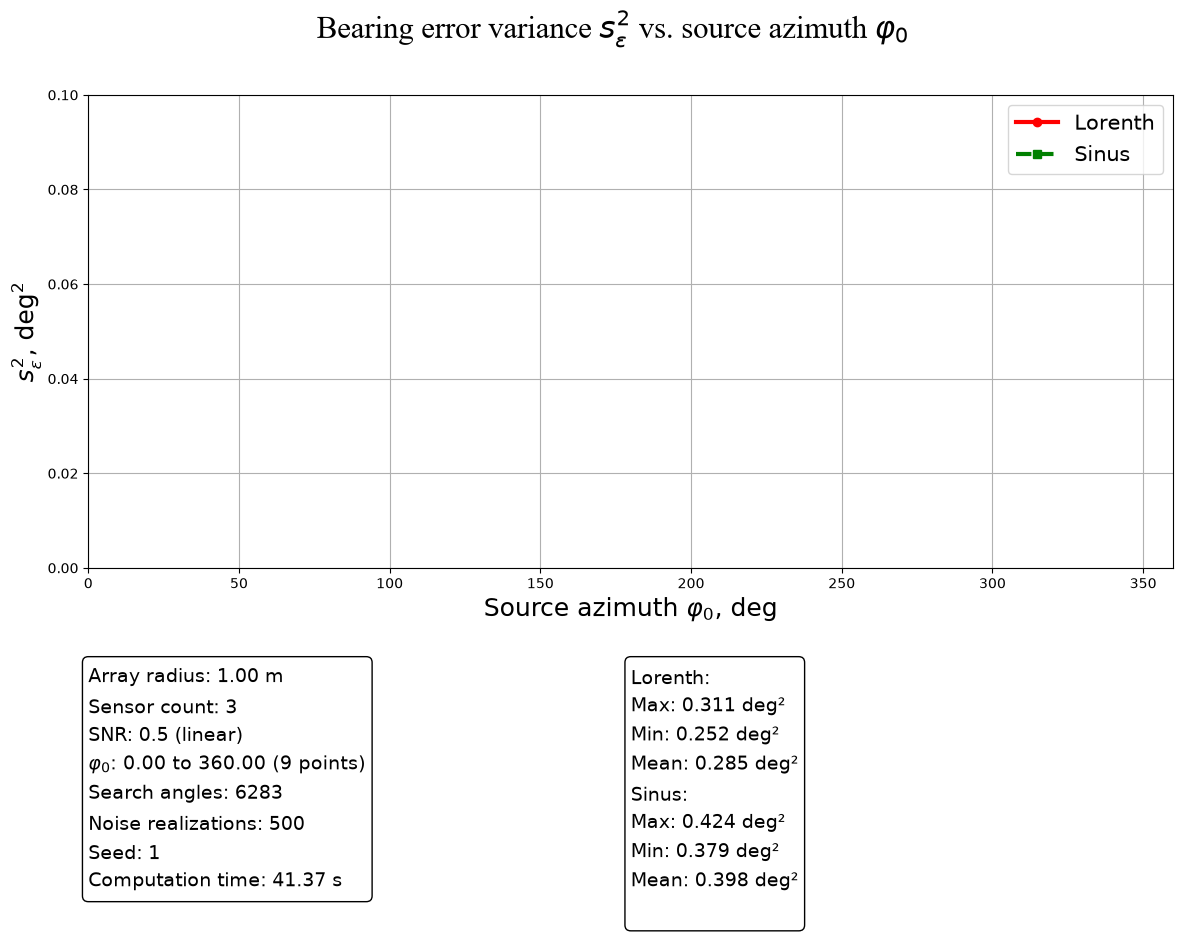

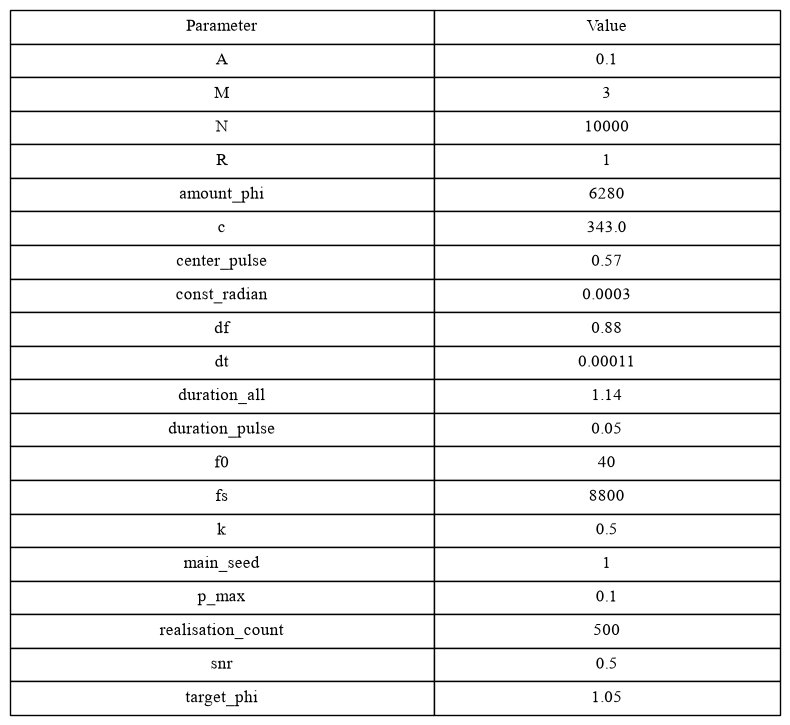

In [10]:
plotting.variance_vs_param(dict_values = {"Lorenth": lorenth_vs_phis,
                                               "Sinus": sinus_vs_phis},
                                config_params = copy(configs),
                                delta_time = delta_time,
                                ylim = (0.00*configs.const_radian, 0.1*configs.const_radian),
                                xlim = (0,360),
                                **parametr_config)
plotting.config_table(configs)